Steps to preprocess VIIRS data for phenology tracking.

Author: Tayler LaSharr

Date: September 2024

In [10]:
## first we will read in necessary python libraries and intialize the GEE module
## you will have to authenticate GEE on your machine to use this code

import ee
import matplotlib.pyplot as plt
from datetime import datetime, timezone
import geopandas as gpd
import pandas as pd
import geemap
import pprint

import json

## if you need to authenticate GEE use this code (will give you a link to allow you to authenticate it online )
# ee.Authenticate()

## initialize the Earth Engine module
ee.Initialize(project='ee-tlasharr')

In [11]:
## set thresholds and things to manipulate

## define the winter period for your study area
start_month_day = '12-01'
end_month_day = '02-28'

## threshold for snow in winter to get the 'baseline' value in winter
snow_threshold = 50

## get the time period we care about (2023 data is still looking pretty weird for VIIRS)
start_date_data = '2018-01-01'
end_date_data = '2019-12-31'


Read in the different data pieces that we care about (VIIRS NDVI, MODIS snow, and mule deer polygons)

Projection of the cooridor shapefile: {'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [1, 0, 0, 0, 1, 0]}


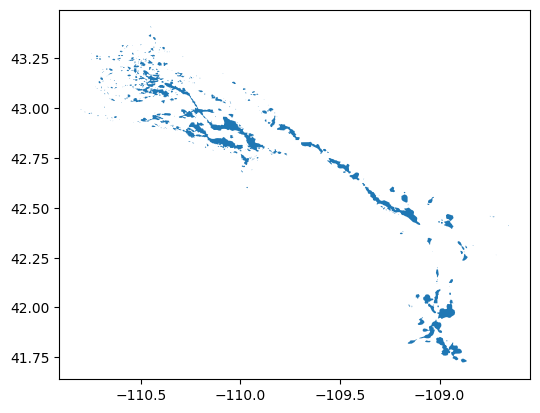

In [22]:
## load in a shapefile or area of interest
## this is an assest that is already loaded into GEE

# md_cooridor = ee.FeatureCollection('projects/ee-tlasharr/assets/AZ_RainbowValley') ## dry af
md_cooridor = ee.FeatureCollection('projects/ee-tlasharr/assets/WY_Sublette') ## "normal" temperate environment
# md_cooridor = ee.FeatureCollection('projects/ee-tlasharr/assets/UT_Paunsaugunt') ## some snow in winter

## get a bounding box for clipping purposes
bounding_box = md_cooridor.geometry().bounds()

## load in the VIIRS data and the MODIS snow data
viirs_ndvi = ee.ImageCollection('NASA/VIIRS/002/VNP13A1') \
                .filterDate(start_date_data, end_date_data) \
                .select('NDVI', 'VI_Quality') \
                .map(lambda image: image.clip(bounding_box))

viirs_evi = ee.ImageCollection('NASA/VIIRS/002/VNP13A1') \
                .filterDate(start_date_data, end_date_data) \
                .select('EVI', 'VI_Quality') \
                .map(lambda image: image.clip(bounding_box))


## right now i'm using the modis snow layer for processing snow, but VIIRS does have one, it's just not yet
## available for GEE

modis_snow = ee.ImageCollection('MODIS/006/MOD10A1') \
                .filterDate(start_date_data, end_date_data) \
                .select('NDSI_Snow_Cover') \
                .map(lambda image: image.clip(bounding_box))

## first see the projection of the shapefile
coordidor_projection = md_cooridor.first().geometry().projection()
print('Projection of the cooridor shapefile:', coordidor_projection.getInfo())

## now we can reproject the shapefile
viirs_projection = viirs_ndvi.first().projection() ## this is the projection of the first image of the modis ndvi data
target_crs = viirs_projection.crs() ## this is the crs from the modis.projection object
target_crs_scale = viirs_projection.nominalScale() ## this is the scale (confused on what this is need to figure this out)

## this is a function to reproject it
def reproject_feature(feature):
    return feature.setGeometry(feature.geometry().transform(target_crs, target_crs_scale))

## this is running the function, so now "reprojected_roi" is the new object we care about
reprojected_roi = md_cooridor.map(reproject_feature)

## then plot it, just to see what's up
geojson = md_cooridor.getInfo()
gdf = gpd.GeoDataFrame.from_features(geojson['features'])
gdf.plot()
plt.show()               

Step 1. Remove low-quality observations with the QA band; this still might need some work. 

In [23]:
## define a function to only return high quality pixels

def quality_mask(image, snow_filter=True):
    ## select the VI_Quality band (not VI_Quality Bitmask if it's not present)
    quality = image.select('VI_Quality')

    ## MODLAND_QA (Bits 0-1) - keep only the pixels where value is 0 or 1 (good quality while also checking other QA things)
    modland_qa = quality.bitwiseAnd(3).lte(1)

    ## VI Usefulness (Bits 2-5) - keep pixels with values <= 2 (higher quality, highest values are worst and it goes to 15, I'm playing with this thershold)
    vi_usefulness = quality.rightShift(2).bitwiseAnd(15).lte(2)

    ## possible Snow/Ice (Bit 14) - mask pixels with snow or ice (might need to get rid of this to deal with winter later??)
    snow_ice = quality.rightShift(14).bitwiseAnd(1).eq(0)

    ## combine all the masks (can turn the snow mask on/off)
    if snow_filter:
        mask = modland_qa.And(vi_usefulness).And(snow_ice)
    else:
        mask = modland_qa.And(vi_usefulness)

    ## apply the mask to the image
    return image.updateMask(mask)

## apply the mask to the VIIRS NDVI collection
viirs_ndvi_filtered = viirs_ndvi.map(lambda img: quality_mask(img, snow_filter=True))


Step 2. Set winter baselines dynamically since winter conditions are variable year to year. This differs from the Bischof methods because winter is not consistent and some winters have snow while others do not. For this step we basically go through 3 different substeps. First, we define the winter period, then we calculate the 'baseline' winter values during that period for all cells that have less than a set amount of snow cover. Finally, if there is snow covering the cells in winter, we will replace them with the 'winter baseline'. We won't set the winter baseline to the baseline for the entire winter because in desert systems there might be green that is more variable.

In [24]:
## function to add a property to the image for if it's winter

def filter_to_winter_period(image_collection, start_month_day, end_month_day):
    """Filters the image collection to the given winter time window."""
    
    ## function to check if the image falls within the specified winter period
    def filter_winter(image):
        image_date = ee.Date(image.get('system:time_start'))
        year = image_date.get('year')

        ## create date ranges for the winter period
        start_date = ee.Date.fromYMD(year, ee.Number.parse(start_month_day.split('-')[0]), ee.Number.parse(start_month_day.split('-')[1]))
        end_date = ee.Date.fromYMD(year.add(1), ee.Number.parse(end_month_day.split('-')[0]), ee.Number.parse(end_month_day.split('-')[1]))

        ## apply the date filter to determine if the image falls within the winter period
        is_winter = ee.Algorithms.If(
            image_date.millis().gte(start_date.millis()).And(image_date.millis().lte(end_date.millis())), 
            True, False
        )

        return image.set('is_winter', is_winter)

    ## apply the filter to the image collection and return only winter images
    winter_filtered = image_collection.map(filter_winter).filter(ee.Filter.eq('is_winter', True))

    return winter_filtered


## run the function
viirs_ndvi_winter = filter_to_winter_period(viirs_ndvi, start_month_day, end_month_day)


In [25]:
## now a function to mask the pixels that have snow above the threshold we care about so we can calculate the 'winter baseline'. this is using
## the entire period, but because VIIRS does not have 9 year data is going to be a shorter time period than the 9 year window that Bischof uses

def mask_snow_using_modis(image, snow_threshold=50):
    
    ## get the VIIRS image date
    viirs_date = ee.Date(image.get('system:time_start'))

    ## get the closest MODIS snow image before and after the VIIRS image date
    modis_snow_image_before = modis_snow.filterDate(start_date_data, viirs_date).sort('system:time_start', False).first()
    modis_snow_image_after = modis_snow.filterDate(viirs_date, end_date_data).sort('system:time_start').first()

    modis_snow_image = ee.Algorithms.If(
        viirs_date.difference(ee.Date(modis_snow_image_before.get('system:time_start')), 'day').abs().lte(
        viirs_date.difference(ee.Date(modis_snow_image_after.get('system:time_start')), 'day').abs()),
        modis_snow_image_before, modis_snow_image_after
    )

    ## mask pixels where snow cover is greater than the threshold
    snow_mask = ee.Image(modis_snow_image).select('NDSI_Snow_Cover').gt(snow_threshold)
    
    ## apply the snow mask to the NDVI image (keep pixels with snow cover below the threshold)
    return image.updateMask(snow_mask.Not())


## apply the snow mask to the winter period NDVI collection
viirs_ndvi_winter_no_snow = viirs_ndvi_winter.map(lambda img: mask_snow_using_modis(img, snow_threshold))


## then calculate the 0.025 percentile of NDVI values in the snow-masked winter NDVI collection
def calculate_baseline(image_collection, quantile=0.025):
    
    ## reduce the image collection to get the 0.025 percentile
    baseline_ndvi = image_collection.select('NDVI').reduce(ee.Reducer.percentile([quantile * 100])).rename('NDVI_baseline')
    return baseline_ndvi

## calculate the baseline for the winter period
winter_baseline_ndvi = calculate_baseline(viirs_ndvi_winter_no_snow, quantile=0.025)



In [41]:
def apply_baseline_correction(image_collection, baseline_image, snow_threshold=50, window_size=2, modis_snow=None):
    """
    Adjust NDVI values based on baseline for snow-covered images and apply a moving window.
    
    Args:
    - image_collection: The collection of NDVI images.
    - baseline_image: The baseline NDVI image calculated for winter.
    - snow_threshold: The snow cover threshold for masking (default is 50%).
    - window_size: The number of surrounding images to check for snow cover (default is 2 images).
    - modis_snow: MODIS snow collection to use for snow cover masking.
    
    Returns:
    - corrected_collection: The image collection with NDVI values adjusted based on the baseline and snow cover.
    """
    
    ## function to get the closest MODIS snow image to the VIIRS image
    def get_closest_modis_snow(image_date):
        modis_snow_before = modis_snow.filterDate('2018-01-01', image_date).sort('system:time_start', False).first()
        modis_snow_after = modis_snow.filterDate(image_date, '2022-12-31').sort('system:time_start').first()

        ## choose the closest MODIS image (either before or after)
        modis_snow_image = ee.Algorithms.If(
            image_date.difference(ee.Date(modis_snow_before.get('system:time_start')), 'day').abs().lte(
            image_date.difference(ee.Date(modis_snow_after.get('system:time_start')), 'day').abs()),
            modis_snow_before, modis_snow_after
        )

        return ee.Image(modis_snow_image)
    
    # function to adjust NDVI for snow-covered pixels
    def adjust_ndvi(image):
        image_date = ee.Date(image.get('system:time_start'))

        ## get the closest MODIS snow image
        modis_snow_image = get_closest_modis_snow(image_date)
        
        ## create a snow mask where snow cover exceeds the threshold
        snow_mask = modis_snow_image.select('NDSI_Snow_Cover').gt(snow_threshold)
        
        ## apply the baseline NDVI where snow mask is true, keep original NDVI otherwise
        adjusted_ndvi = image.select('NDVI').where(snow_mask, baseline_image.select('NDVI_baseline'))
        
        return image.addBands(adjusted_ndvi.rename('NDVI'), overwrite=True)
    
    ## apply the initial snow correction to the entire image collection
    corrected_collection = image_collection.map(adjust_ndvi)
    

    ## the moving window function below is what was causing the memory issues, I have commented it out for now until I can figure out how to
    ## make it more efficient.
    
    ## function to apply the moving window logic for snow-covered pixels
    # def apply_moving_window(image):
    #     image_date = ee.Date(image.get('system:time_start'))
        
    #     ## get surrounding images within the moving window
    #     surrounding_images = image_collection.filter(ee.Filter.date(
    #         image_date.advance(-window_size, 'month'), image_date.advance(window_size, 'month')))
        
    #     ## for each surrounding image, check snow cover and return the snow mask
    #     surrounding_snow_masks = surrounding_images.map(lambda img: 
    #         get_closest_modis_snow(ee.Date(img.get('system:time_start')))
    #         .select('NDSI_Snow_Cover').gt(snow_threshold)
    #     )
        
    #     ## combine the surrounding snow masks using a logical "or" operation
    #     moving_window_mask = surrounding_snow_masks.reduce(ee.Reducer.anyNonZero())
        
    #     ## apply the baseline NDVI where the moving window mask is true
    #     adjusted_ndvi_window = image.select('NDVI').where(moving_window_mask, baseline_image.select('NDVI_baseline'))
        
    #     return image.addBands(adjusted_ndvi_window.rename('NDVI'), overwrite=True)
    
    # ## apply the moving window correction to the collection
    # corrected_collection_with_window = corrected_collection.map(apply_moving_window)
    
    # return corrected_collection_with_window
    return corrected_collection



## apply the baseline correction and moving window (to set the winter min)
viirs_ndvi_corrected = apply_baseline_correction(viirs_ndvi_filtered,
                                                 winter_baseline_ndvi,
                                                 snow_threshold=50,
                                                 window_size=2,
                                                 modis_snow=modis_snow)



Here, we will look at the image collections from GEE to better understand how they are structured and the data that they have. This is purely for troubleshooting and understanding the data and is not necessary for running the pre-processing code.

running into memory issues with the viirs_ndvi_corrected here. Need to do some more exploration with GEE storage and what is happening in the image collections to fix this I think.

In [43]:
## function to check the structure of the image collection

def check_image_collection_structure(image_collection, collection_name):
    
    ## get a sample image to inspect the bands
    sample_image = image_collection.first()
    band_names = sample_image.bandNames().getInfo()
    
    ## gt the total number of images in the collection
    image_count = image_collection.size().getInfo()
    
    ## get the date for each image
    dates = image_collection.aggregate_array('system:time_start').map(lambda d: ee.Date(d).format('YYYY-MM-dd')).getInfo()

    ## check for NAs
    def check_for_na(image):
        ## check how many pixels have NDVI as null
        total_pixels = image.select('NDVI').reduceRegion(
            reducer=ee.Reducer.count(),
            geometry=bounding_box,  # Use your AOI or bounding box
            scale=1000,
            maxPixels=1e13
        ).get('NDVI')
        
        ## count non-missing pixels (valid NDVI values)
        valid_pixels = image.select('NDVI').reduceRegion(
            reducer=ee.Reducer.count(),
            geometry=bounding_box,  # Use your AOI or bounding box
            scale=1000,
            maxPixels=1e13
        ).get('NDVI')

    ## map over collection to get NAs
        na_pixels = ee.Number(total_pixels).subtract(valid_pixels)

        return ee.Feature(None, {'na_pixels': na_pixels, 'date': image.date().format('YYYY-MM-dd')})
    
    ## map over the collection to get NA values for each image
    na_values = image_collection.map(check_for_na).getInfo()
    na_counts = [(feature['properties']['date'], feature['properties']['na_pixels']) for feature in na_values['features']]

    ## print the collected information
    print(f"Collection: {collection_name}")
    print(f"Band names: {band_names}")
    print(f"Total number of images: {image_count}")
    print(f"Dates of images: {dates[:5]}...")  # Print first 5 dates as a preview
    print(f"NDVI NA/Null pixel counts (first 5): {na_counts[:5]}...")  # Preview first 5 images' NA counts
    print("\n")

## run the function for each image collection
check_image_collection_structure(viirs_ndvi, "VIIRS NDVI (Raw)")
check_image_collection_structure(viirs_ndvi_filtered, "VIIRS NDVI (Filtered)")
check_image_collection_structure(viirs_ndvi_corrected, "VIIRS NDVI (Corrected)")

Collection: VIIRS NDVI (Raw)
Band names: ['NDVI', 'VI_Quality']
Total number of images: 91
Dates of images: ['2018-01-09', '2018-01-17', '2018-01-25', '2018-02-02', '2018-02-10']...
NDVI NA/Null pixel counts (first 5): [('2018-01-09', 0), ('2018-01-17', 0), ('2018-01-25', 0), ('2018-02-02', 0), ('2018-02-10', 0)]...


Collection: VIIRS NDVI (Filtered)
Band names: ['NDVI', 'VI_Quality']
Total number of images: 91
Dates of images: ['2018-01-09', '2018-01-17', '2018-01-25', '2018-02-02', '2018-02-10']...
NDVI NA/Null pixel counts (first 5): [('2018-01-09', 0), ('2018-01-17', 0), ('2018-01-25', 0), ('2018-02-02', 0), ('2018-02-10', 0)]...


Collection: VIIRS NDVI (Corrected)
Band names: ['NDVI', 'VI_Quality']
Total number of images: 91
Dates of images: ['2018-01-09', '2018-01-17', '2018-01-25', '2018-02-02', '2018-02-10']...
NDVI NA/Null pixel counts (first 5): [('2018-01-09', 0), ('2018-01-17', 0), ('2018-01-25', 0), ('2018-02-02', 0), ('2018-02-10', 0)]...




In [45]:
## split the area of interest
def split_aoi(bounding_box, num_tiles_x, num_tiles_y):
    
    ## get the bounding box of the AOI
    bounds = bounding_box.bounds()

    ## get the coordinates of the bounding box
    coords = bounds.coordinates().get(0).getInfo()

    ## calculate the step sizes for each tile
    x_step = (coords[2][0] - coords[0][0]) / num_tiles_x
    y_step = (coords[2][1] - coords[0][1]) / num_tiles_y

    smaller_aois = []
    for i in range(num_tiles_x):
        for j in range(num_tiles_y):
            
            ## define the corners of the grid cell
            x_min = coords[0][0] + i * x_step
            y_min = coords[0][1] + j * y_step
            x_max = x_min + x_step
            y_max = y_min + y_step

            ## create the smaller AOI tile
            smaller_aoi = ee.Geometry.Rectangle([x_min, y_min, x_max, y_max])
            smaller_aois.append(smaller_aoi)

    return smaller_aois

## number of times we want to split it into
smaller_aois = split_aoi(bounding_box, num_tiles_x=10, num_tiles_y=10)

## process the area in batches (I was hitting some meory issues with GEE)
## this takes about ~ 15 minutes to run for the sublette herd
def extract_ndvi_batched(image_collection, smaller_aois, batch_size=2):
    """
    Process NDVI values for smaller AOIs in batches to avoid EEException (Too many concurrent aggregations).
    
    Args:
    - image_collection: The collection of images.
    - smaller_aois: List of smaller AOIs.
    - batch_size: The number of AOIs to process in each batch.
    
    Returns:
    - final_feature_collection: The combined FeatureCollection of NDVI results.
    """
    all_results = []
    total_tiles = len(smaller_aois)
    
    ## process AOIs in batches
    for i in range(0, total_tiles, batch_size):
        
        ## get the batch of AOIs
        batch_aoi = smaller_aois[i:i + batch_size]
        print(f"Processing AOI batch {i//batch_size + 1}/{(total_tiles + batch_size - 1)//batch_size}")

        ## apply the reducer over this batch
        for image in image_collection.toList(image_collection.size()).getInfo():
            
            ## extract image date
            image_date = ee.Date(image['properties']['system:time_start']).format('YYYY-MM-dd').getInfo()
            image_id = ee.Image(image['id'])

            ## use reduceRegions to apply the reducer to the batch of smaller AOIs
            reduced_tiles = image_id.reduceRegions(
                collection=ee.FeatureCollection(batch_aoi),
                reducer=ee.Reducer.mean(),
                scale=500
            )

            ## map over reduced_tiles to extract NDVI values and create a list of dictionaries
            def extract_ndvi(feature):
                ndvi = feature.get('mean')
                return ee.Feature(None, {'NDVI': ndvi, 'date': image_date})

            ## collect results as a FeatureCollection
            reduced_results = reduced_tiles.map(extract_ndvi)
            all_results.append(reduced_results)

    ## combine all the results into one FeatureCollection
    final_feature_collection = ee.FeatureCollection(all_results).flatten()
    
    return final_feature_collection

## process the smaller AOIs
ndvi_raw_batched = extract_ndvi_batched(viirs_ndvi, smaller_aois, batch_size=5)
ndvi_filtered_batched = extract_ndvi_batched(viirs_ndvi_filtered, smaller_aois, batch_size=5)
ndvi_corrected_batched = extract_ndvi_batched(viirs_ndvi_corrected, smaller_aois, batch_size=2)

print(ndvi_raw_batched.first().getInfo())
print(ndvi_filtered_batched.first().getInfo())
print(ndvi_corrected_batched.first().getInfo())

## convert to pd dataframe
def convert_to_dataframe(feature_collection):

    ## check if feature collection has features
    features = feature_collection.getInfo().get('features', [])
    if not features:
        print("No features found in the collection")
        return pd.DataFrame()  # Return empty dataframe if no features
    
    data = []
    for f in features:
        properties = f['properties']
        ndvi = properties.get('NDVI')
        date = properties.get('date')
        
        if ndvi is not None and date is not None:
            data.append({'date': date, 'NDVI': ndvi})
    
    return pd.DataFrame(data)

## convert the results for the raw, filtered, and corrected NDVI values
df_raw = convert_to_dataframe(ndvi_raw_batched)
df_filtered = convert_to_dataframe(ndvi_filtered_batched)
df_corrected = convert_to_dataframe(ndvi_corrected_batched)

## preview the DataFrames
print("Raw DataFrame head:")
print(df_raw.head())

print("\nFiltered DataFrame head:")
print(df_filtered.head())

print("\nCorrected DataFrame head:")
print(df_corrected.head())

## the dataframes are empty so something weird is happening here, need to fix this.

Processing AOI batch 1/20
Processing AOI batch 2/20
Processing AOI batch 3/20
Processing AOI batch 4/20
Processing AOI batch 5/20
Processing AOI batch 6/20
Processing AOI batch 7/20
Processing AOI batch 8/20
Processing AOI batch 9/20
Processing AOI batch 10/20
Processing AOI batch 11/20
Processing AOI batch 12/20
Processing AOI batch 13/20
Processing AOI batch 14/20
Processing AOI batch 15/20
Processing AOI batch 16/20
Processing AOI batch 17/20
Processing AOI batch 18/20
Processing AOI batch 19/20
Processing AOI batch 20/20
Processing AOI batch 1/20
Processing AOI batch 2/20
Processing AOI batch 3/20
Processing AOI batch 4/20
Processing AOI batch 5/20
Processing AOI batch 6/20
Processing AOI batch 7/20
Processing AOI batch 8/20
Processing AOI batch 9/20
Processing AOI batch 10/20
Processing AOI batch 11/20
Processing AOI batch 12/20
Processing AOI batch 13/20
Processing AOI batch 14/20
Processing AOI batch 15/20
Processing AOI batch 16/20
Processing AOI batch 17/20
Processing AOI batc

Everything below here is not functional. I need to fix the first part of the code before moving to the next step.

Step 3. Apply a smoothing function (moving median window with a search window of 3)

In [19]:
def apply_image_median(image_collection, window_size=3):
    
    ## define a function to apply median filtering using a fixed number of images around each image
    def smooth_image(current_image):
        
        ## get the list of all images in the collection, sorted by date
        all_images = image_collection.sort('system:time_start')
        all_images_list = all_images.toList(all_images.size())  # Convert to a list

        ## get the index of the current image
        image_index = all_images_list.indexOf(current_image)
        
        ## calculate half of the window size
        half_window = ee.Number(window_size // 2)

        ## define the start and end indices for the window (centered on the current image)
        ## ensure start_index is not less than 0
        start_index = ee.Number(image_index).subtract(half_window).max(0)

        ## ensure end_index is not greater than the total number of images
        end_index = ee.Number(image_index).add(half_window).min(all_images.size().subtract(1))

        ## create a list of images within the window
        window_images = all_images_list.slice(start_index, end_index.add(1))  # Include the end image
        window_collection = ee.ImageCollection.fromImages(window_images)

        ## compute the median of the selected images
        median_image = window_collection.median()

        ## return the median-smoothed image, keeping the original properties
        return median_image.copyProperties(current_image, current_image.propertyNames())

    ## apply the smoothing function over the entire image collection
    smoothed_collection = image_collection.map(smooth_image)

    return smoothed_collection

## apply the smoothing function to the processed_ndvi collection
smoothed_ndvi = apply_image_median(processed_ndvi, window_size=3)


NameError: name 'processed_ndvi' is not defined

In [15]:
## function to extract NDVI values for multiple random points from an image collection
def extract_ndvi_for_points(image_collection, points):
    
    def extract_for_point(image):
        
        ## iterate over the points (FeatureCollection) and extract NDVI for each point
        def extract_for_feature(feature):

            ## reduce the region for each point and get the mean NDVI value
            ndvi_value = image.reduceRegion(
                reducer=ee.Reducer.mean(),
                geometry=feature.geometry(),
                scale=500 
            )

            date = ee.Date(image.get('system:time_start')).format('YYYY-MM-dd')
            return feature.set({'NDVI': ndvi_value.get('NDVI'), 'date': date})

        ## map the function over all points
        return points.map(extract_for_feature)

    ## apply the extraction function over the entire image collection
    ## note: we flattened the results so they return as one FeatureCollection
    ndvi_values = image_collection.map(extract_for_point).flatten()
    
    return ndvi_values


## extract NDVI values for random points from each collection
smoothed_ndvi_values = extract_ndvi_for_points(smoothed_ndvi, random_points)
processed_ndvi_values = extract_ndvi_for_points(processed_ndvi, random_points)
viirs_ndvi_values = extract_ndvi_for_points(viirs_ndvi, random_points)


In [16]:
smoothed_ndvi_values_info = smoothed_ndvi_values.getInfo()
processed_ndvi_values_info = processed_ndvi_values.getInfo()
viirs_ndvi_values_info = viirs_ndvi_values.getInfo()

## get the infomration from the random_points object
random_points_info = random_points.getInfo()['features']

## function to get dataframes
def convert_to_dataframe(ndvi_values_info, point_ids):
    
    ## create a list to hold the processed data
    data = []
    
    ## loop through each feature and extract the NDVI and date properties for each point
    for i, point_id in enumerate(point_ids):
        
        ## get the corresponding features for the current point
        
        for feature in ndvi_values_info['features']:
            
            ## extract NDVI and date from properties
            properties = feature.get('properties', {})
            ndvi = properties.get('NDVI', None)
            date_str = properties.get('date')

            ## parse the date string
            try:
                date = datetime.strptime(date_str, '%Y-%m-%d')  ## convert to datetime object
            except:
                date = None  ## if the parsing fails, set the date as None

            ## add the extracted data along with the point_id
            if ndvi is not None and date is not None:
                data.append({'date': date, 'NDVI': ndvi, 'point_id': point_id})
    
    ## convert the list into a Pandas DataFrame
    ndvi_df = pd.DataFrame(data)
    
    ## remove duplicates (same point, same date) by keeping only the first occurrence
    ndvi_df = ndvi_df.drop_duplicates(subset=['date', 'point_id'])
    
    ## sort the DataFrame by point_id and date
    ndvi_df = ndvi_df.sort_values(by=['point_id', 'date'])

    return ndvi_df


## convert the NDVI values to DataFrames for each collection
smoothed_ndvi_df = convert_to_dataframe(smoothed_ndvi_values_info, point_ids)
processed_ndvi_df = convert_to_dataframe(processed_ndvi_values_info, point_ids)
viirs_ndvi_df = convert_to_dataframe(viirs_ndvi_values_info, point_ids)

## print the first few rows of the DataFrames to verify
print(smoothed_ndvi_df.head())
print(processed_ndvi_df.head())
print(viirs_ndvi_df.head())

EEException: Collection.toList: Error in map(ID=2018_03_06):
Image.rename: The number of names (1) must match the number of bands (2).

In [17]:
## subset the data to get the first point
smoothed_point_0_df = smoothed_ndvi_df[smoothed_ndvi_df['point_id'] == 'point_0']
processed_point_0_df = processed_ndvi_df[processed_ndvi_df['point_id'] == 'point_0']
viirs_point_0_df = viirs_ndvi_df[viirs_ndvi_df['point_id'] == 'point_0']

## function to plot NDVI time series for one point
def plot_ndvi(df, title, color):
    plt.plot(df['date'], df['NDVI'], linestyle='-', label=title, color=color)

## plot the NDVI time series for the first point from each DataFrame
plt.figure(figsize=(10, 6))

## plot original VIIRS NDVI
plt.plot(viirs_point_0_df['date'], viirs_point_0_df['NDVI'], label='Original VIIRS NDVI', color='red', alpha=0.5, linestyle='-')

##  processed NDVI (snow and bad data removed)
plt.plot(processed_point_0_df['date'], processed_point_0_df['NDVI'], label='Processed NDVI', color='green', alpha=0.5, linestyle='-')

## smoothed data
plt.plot(smoothed_point_0_df['date'], smoothed_point_0_df['NDVI'], label='Smoothed NDVI', color='blue', alpha=0.5, linestyle='-')

## add titles and labels
plt.title('NDVI Time Series for Point 0')
plt.xlabel('Date')
plt.ylabel('NDVI')
plt.legend()
plt.grid(True)

## show the plot
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

NameError: name 'smoothed_ndvi_df' is not defined

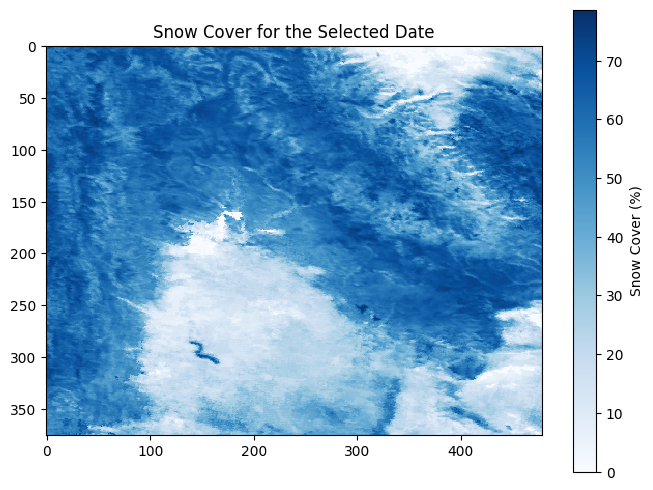

        date  NDVI_original point_id_original  NDVI_processed  \
0 2018-01-09        -0.0195           point_0         -0.0195   
1 2018-01-09        -0.0195           point_0         -0.0195   
2 2018-01-09        -0.0195           point_0         -0.0195   
3 2018-01-09        -0.0195           point_0         -0.0195   
4 2018-01-09        -0.0195           point_0         -0.0195   

  point_id_processed  
0            point_0  
1            point_1  
2            point_2  
3            point_3  
4            point_4  


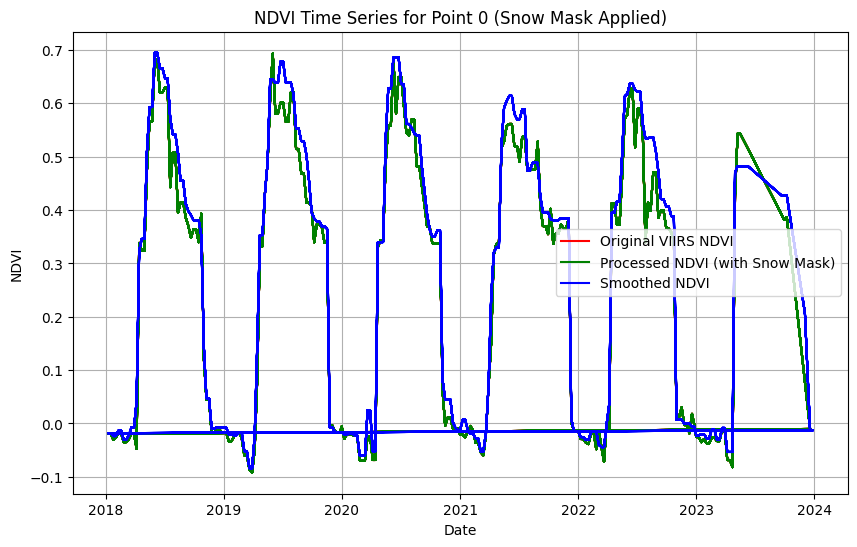

In [23]:
# Function to visualize snow cover for a specific date
def visualize_snow_cover(snow_cover):
    # Download the snow cover image as a NumPy array
    snow_cover_array = geemap.ee_to_numpy(snow_cover, region=md_cooridor.geometry(), scale=500)
    
    # Plot the snow cover mask
    plt.figure(figsize=(8, 6))
    plt.imshow(snow_cover_array, cmap='Blues', interpolation='none')
    plt.title('Snow Cover for the Selected Date')
    plt.colorbar(label='Snow Cover (%)')
    plt.show()

# Get the snow cover data for January 2018
snow_cover = modis_snow.filterDate('2018-01-01', '2018-01-31').mean()

# Visualize the snow cover
visualize_snow_cover(snow_cover)

def apply_snow_mask(ndvi_collection, snow_threshold=50):
    def mask_snow(image):
        # Calculate snow cover mean for the date of the image
        snow_cover = modis_snow.mean().gt(snow_threshold)  # Threshold of 50% snow cover
        return image.updateMask(snow_cover.Not())  # Mask out areas with snow cover

    # Apply the snow mask to each NDVI image
    return ndvi_collection.map(mask_snow)

# Apply the snow mask to the original VIIRS NDVI data
viirs_ndvi_filtered_with_snow_mask = apply_snow_mask(viirs_ndvi)

# Recalculate the processed NDVI by applying the snow mask and other filters
processed_ndvi_with_snow = apply_snow_mask(processed_ndvi)

# Extract the NDVI values after applying the snow mask
processed_ndvi_values_with_snow = extract_ndvi_for_points(processed_ndvi_with_snow, random_points)

# Compare the original and processed NDVI values again
ndvi_comparison_df_with_snow = pd.merge(viirs_ndvi_df, processed_ndvi_df, on='date', suffixes=('_original', '_processed'))
print(ndvi_comparison_df_with_snow.head())

# Plot the NDVI time series for point 0, including the snow mask processing
plt.figure(figsize=(10, 6))
plt.plot(viirs_ndvi_df['date'], viirs_ndvi_df['NDVI'], label='Original VIIRS NDVI', color='red', linestyle='-')
plt.plot(processed_ndvi_df['date'], processed_ndvi_df['NDVI'], label='Processed NDVI (with Snow Mask)', color='green', linestyle='-')
plt.plot(smoothed_ndvi_df['date'], smoothed_ndvi_df['NDVI'], label='Smoothed NDVI', color='blue', linestyle='-')
plt.xlabel('Date')
plt.ylabel('NDVI')
plt.title('NDVI Time Series for Point 0 (Snow Mask Applied)')
plt.legend()
plt.grid(True)
plt.show()